# Notebook 02 — Static Baseline Routing

## Purpose
Compute static Dijkstra shortest paths on all 50 synthetic networks and save the results for comparison in Notebook 03.

## What this notebook does
1. Loads the 50 networks from `data/raw/`
2. Demonstrates the static routing algorithm on trial 0
3. Visualises the static shortest path on trial 0
4. Runs all 50 trials in a batch and saves to `data/processed/static_results.csv`
5. Plots the distribution of static costs
6. Computes centrality measures as a supporting analysis

In [1]:
import sys
from pathlib import Path

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
sys.path.insert(0, str(project_root))

import pickle
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from src.config import (
    SEED, NUM_TRIALS, DATA_RAW_DIR, DATA_PROCESSED_DIR,
    FIGURES_DIR, ensure_directories
)
from src.routing import static_routing
from src.visualize import plot_network_with_path

ensure_directories()
print(f"Project root:    {project_root}")
print(f"Data raw dir:    {DATA_RAW_DIR}")
print(f"Data proc dir:   {DATA_PROCESSED_DIR}")

Project root:    /Users/johen/Documents/emergency-graph-routing
Data raw dir:    /Users/johen/Documents/emergency-graph-routing/data/raw
Data proc dir:   /Users/johen/Documents/emergency-graph-routing/data/processed


In [2]:
# Load all 50 networks from disk
all_networks = []
for i in range(NUM_TRIALS):
    path = DATA_RAW_DIR / f"network_{i:02d}.pkl"
    with open(path, "rb") as f:
        G = pickle.load(f)
    all_networks.append(G)

print(f"Loaded {len(all_networks)} networks")
print(f"First network:  {all_networks[0].number_of_nodes()} nodes, "
      f"{all_networks[0].number_of_edges()} edges")

Loaded 50 networks
First network:  15 nodes, 40 edges


In [3]:
# Test static routing on trial 0 with fixed source/target
SOURCE = 0
TARGET = 14

G0 = all_networks[0]
path0, cost0 = static_routing(G0, source=SOURCE, target=TARGET)

print(f"Source: {SOURCE} -> Target: {TARGET}")
print(f"Path:   {path0}")
print(f"Cost:   {cost0:.2f} minutes")
print(f"Hops:   {len(path0) - 1}")

Source: 0 -> Target: 14
Path:   [0, 3, 9, 14]
Cost:   42.00 minutes
Hops:   3


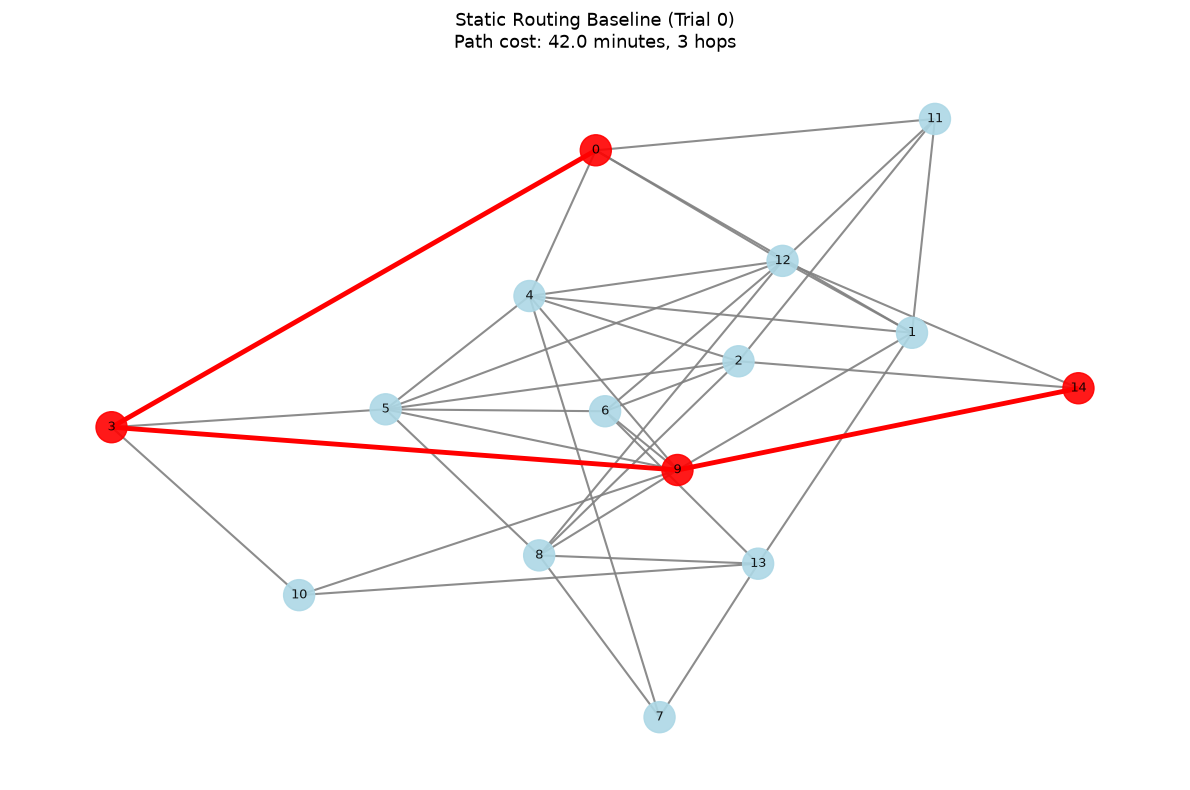

[Figure saved] /Users/johen/Documents/emergency-graph-routing/figures/02_static_routing.png


In [4]:
# Visualise the static shortest path on trial 0
fig_path = FIGURES_DIR / "02_static_routing.png"
plot_network_with_path(
    G0,
    path=path0,
    title=f"Static Routing Baseline (Trial 0)\n"
          f"Path cost: {cost0:.1f} minutes, {len(path0) - 1} hops",
    filename=fig_path,
)

## Batch Processing — All 50 Trials

For each trial, pick a random source/target pair (deterministic via the trial seed), compute the static shortest path, and record:

- `trial` — trial index
- `source`, `target` — endpoints
- `static_cost` — total travel time (minutes)
- `static_path_length` — number of hops

In [5]:
# Run static routing on all 50 trials
results = []
for i, G in enumerate(all_networks):
    rng = random.Random(SEED + i)
    nodes = list(G.nodes())
    source, target = rng.sample(nodes, 2)

    path, cost = static_routing(G, source=source, target=target)

    results.append({
        "trial": i,
        "source": source,
        "target": target,
        "static_cost": cost,
        "static_path_length": (len(path) - 1) if path else None,
    })

static_df = pd.DataFrame(results)
print(f"Completed {len(static_df)} trials")
print(static_df.head(10).to_string(index=False))

Completed 50 trials
 trial  source  target  static_cost  static_path_length
     0      10       1         39.0                   2
     1       0       4         33.0                   2
     2       6       8          6.0                   1
     3       4       6         24.0                   2
     4      14       1         17.0                   1
     5       5       1         22.0                   3
     6       8       5         17.0                   1
     7       1       5         17.0                   2
     8       7      13         21.0                   3
     9       3      13         27.0                   2


In [6]:
# Save to CSV
csv_path = DATA_PROCESSED_DIR / "static_results.csv"
static_df.to_csv(csv_path, index=False)
print(f"Saved: {csv_path}")
print(f"Rows:  {len(static_df)}")

Saved: /Users/johen/Documents/emergency-graph-routing/data/processed/static_results.csv
Rows:  50


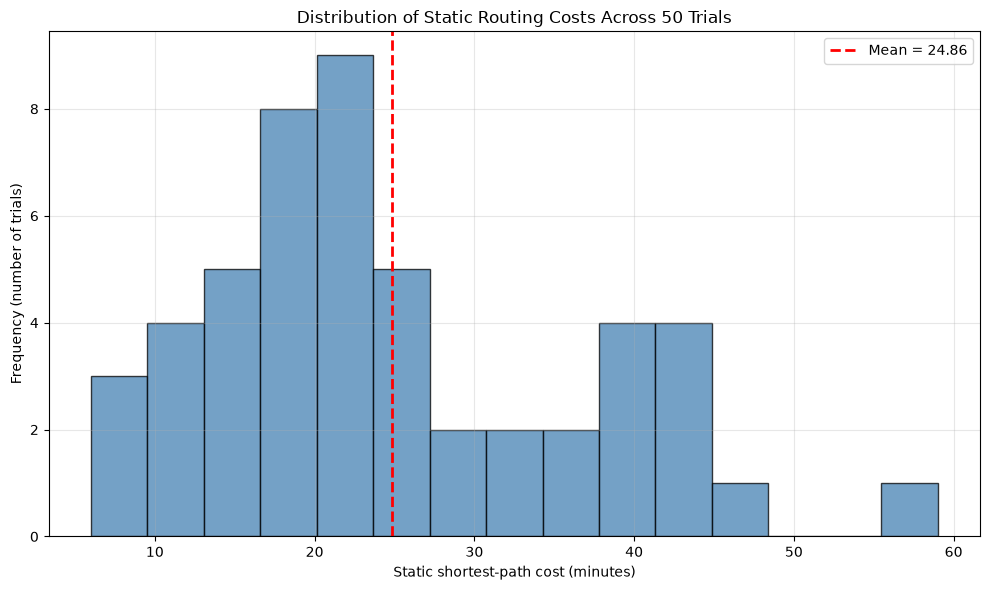

[Figure saved] /Users/johen/Documents/emergency-graph-routing/figures/04_cost_distribution.png

Mean:   24.86
Median: 22.50
Std:    11.73


In [7]:
# Plot distribution of static routing costs
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(static_df["static_cost"], bins=15, color="steelblue",
        edgecolor="black", alpha=0.75)
ax.axvline(static_df["static_cost"].mean(), color="red",
           linestyle="--", linewidth=2,
           label=f"Mean = {static_df['static_cost'].mean():.2f}")
ax.set_xlabel("Static shortest-path cost (minutes)")
ax.set_ylabel("Frequency (number of trials)")
ax.set_title("Distribution of Static Routing Costs Across 50 Trials")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()

hist_path = FIGURES_DIR / "04_cost_distribution.png"
plt.savefig(hist_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"[Figure saved] {hist_path}")
print(f"\nMean:   {static_df['static_cost'].mean():.2f}")
print(f"Median: {static_df['static_cost'].median():.2f}")
print(f"Std:    {static_df['static_cost'].std():.2f}")

In [8]:
# Supporting analysis: centrality measures on trial 0
degree_c = nx.degree_centrality(G0)
betweenness_c = nx.betweenness_centrality(G0, weight="weight")

top_deg = sorted(degree_c.items(), key=lambda x: x[1], reverse=True)[:3]
top_btw = sorted(betweenness_c.items(), key=lambda x: x[1], reverse=True)[:3]

print("Top-3 by degree centrality:")
for node, val in top_deg:
    print(f"  Node {node}: {val:.3f}")

print("\nTop-3 by betweenness centrality:")
for node, val in top_btw:
    print(f"  Node {node}: {val:.3f}")

Top-3 by degree centrality:
  Node 9: 0.571
  Node 12: 0.571
  Node 4: 0.500

Top-3 by betweenness centrality:
  Node 9: 0.258
  Node 4: 0.181
  Node 8: 0.121


In [9]:
# Quick sensitivity check: does the static path change with source/target?
print("Sample static routes for trial 0 across node pairs:\n")
for src, tgt in [(0, 14), (1, 13), (2, 12), (3, 11)]:
    p, c = static_routing(G0, source=src, target=tgt)
    print(f"  {src:2d} -> {tgt:2d} | cost = {c:6.2f} | hops = {len(p) - 1}")

Sample static routes for trial 0 across node pairs:

   0 -> 14 | cost =  42.00 | hops = 3
   1 -> 13 | cost =  26.00 | hops = 1
   2 -> 12 | cost =  21.00 | hops = 2
   3 -> 11 | cost =  29.00 | hops = 2


## Summary

✅ Loaded all 50 networks  
✅ Computed static Dijkstra shortest paths on every trial  
✅ Saved results to `data/processed/static_results.csv`  
✅ Saved path visualisation: `figures/02_static_routing.png`  
✅ Saved cost histogram: `figures/04_cost_distribution.png`  
✅ Computed degree and betweenness centrality on trial 0

**Key observation:** The static model always picks the same route regardless of node capacity or load. When a facility is overloaded, a real dispatcher would reroute — but the static baseline cannot represent this. This is exactly the gap **Notebook 03** will address.